# Trabajo Práctico Integrador — Redes Neuronales
## Clasificación del fármaco recetado a un paciente con un Perceptrón Multicapa (MLP)

**Alumno:** Adison Espinoza
**Tecnicatura Universitaria en Ciencia de Datos — Universidad Nacional de Chilecito**

Contenido:
1. Presentación del dataset y del problema
2. Análisis exploratorio
3. Preparación de los datos (ingeniería de variables, codificación, división y estandarización)
4. Diseño de la red neuronal y búsqueda de hiperparámetros
5. Entrenamiento y predicciones
6. Evaluación e interpretación de resultados
7. Conclusiones y limitaciones

## 0. Librerías
Se usan las mismas librerías vistas en la cursada: **pandas** y **numpy** para manejar los datos, **matplotlib** para los gráficos y **scikit-learn** para el preprocesamiento, la red neuronal (`MLPClassifier`) y las métricas.

In [24]:
%pip install scikit-learn pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import warnings
warnings.filterwarnings("ignore")   # oculta avisos de convergencia durante la búsqueda de hiperparámetros

SEMILLA = 42   # semilla fija para que los resultados sean reproducibles

## 1. Presentación del dataset y del problema

**Fuente:** *Drug Classification* (conocido como `drug200`), dataset público disponible en Kaggle.

Cada fila es un **paciente** y la columna `Drug` indica qué **fármaco** le fue recetado (5 opciones: drugA, drugB, drugC, drugX y drugY).

| Variable | Tipo | Descripción |
|---|---|---|
| `Age` | numérica | Edad del paciente (años) |
| `Sex` | categórica (F / M) | Sexo |
| `BP` | categórica (LOW / NORMAL / HIGH) | Presión arterial |
| `Cholesterol` | categórica (NORMAL / HIGH) | Nivel de colesterol |
| `Na` | numérica | Concentración de sodio en sangre |
| `K` | numérica | Concentración de potasio en sangre |
| **`Drug`** | **categórica (5 clases)** | **Variable objetivo: fármaco recetado** |

**Tipo de problema:** es un problema de **clasificación multiclase**, porque la variable objetivo no es un número continuo, sino una categoría entre 5 posibles. El modelo tiene que asignar a cada paciente una de esas clases.

In [26]:
df = pd.read_csv("Drugs5.csv")
print("Dimensiones:", df.shape)
df.head()

Dimensiones: (200, 7)


,Age,Sex,BP,Cholesterol,Na,K,Drug
0,23,F,HIGH,HIGH,0.792535,0.031258,drugY
1,47,M,LOW,HIGH,0.739309,0.056468,drugC
2,47,M,LOW,HIGH,0.697269,0.068944,drugC
3,28,F,NORMAL,HIGH,0.563682,0.072289,drugX
4,61,F,LOW,HIGH,0.559294,0.030998,drugY


In [27]:
df.info()
print("\nValores faltantes por columna:")
print(df.isna().sum())
print("\nFilas duplicadas:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          200 non-null    int64  
 1   Sex          200 non-null    str    
 2   BP           200 non-null    str    
 3   Cholesterol  200 non-null    str    
 4   Na           200 non-null    float64
 5   K            200 non-null    float64
 6   Drug         200 non-null    str    
dtypes: float64(2), int64(1), str(4)
memory usage: 11.1 KB

Valores faltantes por columna:
Age            0
Sex            0
BP             0
Cholesterol    0
Na             0
K              0
Drug           0
dtype: int64

Filas duplicadas: 0


## 2. Análisis exploratorio

### 2.1 Distribución de la variable objetivo

Drug
drugY    91
drugX    54
drugA    23
drugC    16
drugB    16
Name: count, dtype: int64

Proporción (%):
Drug
drugY    45.5
drugX    27.0
drugA    11.5
drugC     8.0
drugB     8.0
Name: count, dtype: float64


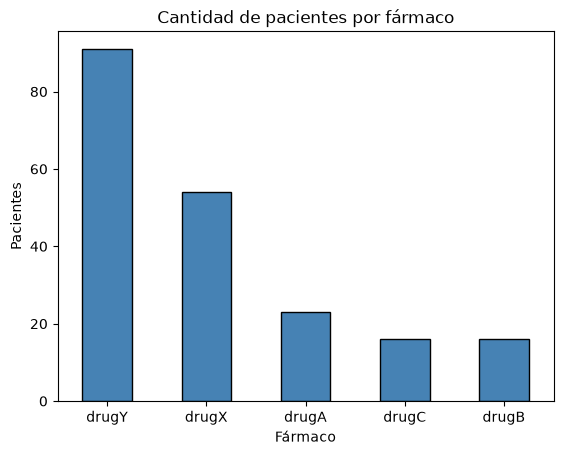

In [28]:
conteo = df["Drug"].value_counts()
print(conteo)
print("\nProporción (%):")
print((conteo / len(df) * 100).round(1))

conteo.plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("Cantidad de pacientes por fármaco")
plt.xlabel("Fármaco"); plt.ylabel("Pacientes")
plt.xticks(rotation=0)
plt.show()

**Observación:** las clases están **desbalanceadas**. drugY representa casi la mitad de los casos y drugB y drugC solo un 8 % cada una. Esto lleva a dos decisiones:
- dividir los datos de forma **estratificada**, para que train y test mantengan las mismas proporciones;
- **no evaluar solo con accuracy**: un modelo que respondiera siempre "drugY" ya acertaría alrededor del 45 %. Por eso también se miran el F1 por clase, el F1 macro y la matriz de confusión.

### 2.2 Variables numéricas

In [29]:
df.describe()

,Age,Na,K
count,200.000000,200.000000,200.000000
mean,44.315000,0.697095,0.050174
std,16.544315,0.118907,0.017611
min,15.000000,0.500169,0.020022
25%,31.000000,0.583887,0.035054
50%,45.000000,0.721853,0.049663
75%,58.000000,0.801494,0.066000
max,74.000000,0.896056,0.079788


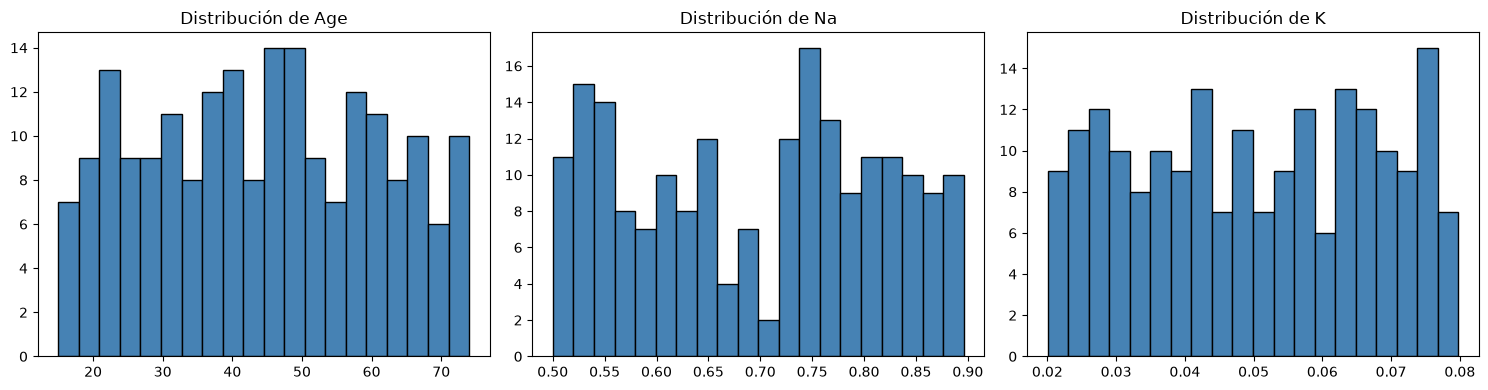

In [30]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for eje, col in zip(ejes, ["Age", "Na", "K"]):
    eje.hist(df[col], bins=20, color="steelblue", edgecolor="black")
    eje.set_title(f"Distribución de {col}")
plt.tight_layout()
plt.show()

Las tres variables numéricas tienen escalas muy distintas: la edad va de 15 a 74, mientras que Na y K son valores menores a 1. Esto justifica **estandarizarlas** más adelante, porque la red neuronal aprende con descenso de gradiente y es sensible a la escala de las entradas.

### 2.3 Relación sodio / potasio
En el contexto médico se suele usar el **cociente Na/K**. Se crea esa variable y se compara entre fármacos:

         min    max   mean
Drug                      
drugA   6.27  13.97  10.92
drugB   8.62  14.24  11.52
drugC   6.77  14.16  10.63
drugX   6.68  14.64  10.65
drugY  15.02  38.25  22.37


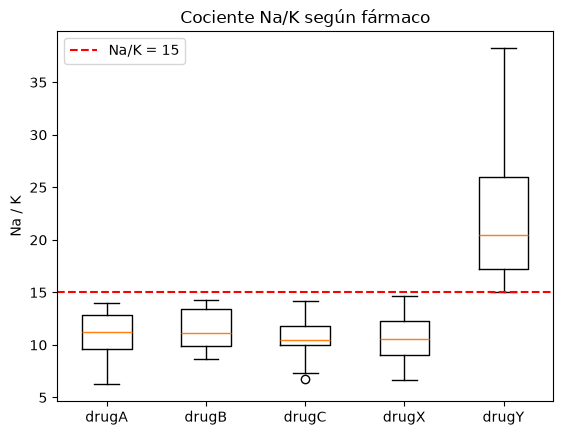

In [31]:
df["Na_to_K"] = df["Na"] / df["K"]

print(df.groupby("Drug")["Na_to_K"].agg(["min", "max", "mean"]).round(2))

farmacos = sorted(df["Drug"].unique())
plt.boxplot([df.loc[df["Drug"] == f, "Na_to_K"] for f in farmacos])
plt.xticks(range(1, len(farmacos) + 1), farmacos)
plt.axhline(15, color="red", linestyle="--", label="Na/K = 15")
plt.title("Cociente Na/K según fármaco")
plt.ylabel("Na / K"); plt.legend()
plt.show()

**Hallazgo clave:** **todos** los pacientes con Na/K mayor a 15 recibieron drugY, y ningún otro fármaco supera ese valor. El cociente separa una clase entera, algo que Na y K por separado no muestran con tanta claridad. Por eso se decide **incorporar `Na_to_K` como variable de entrada** (ingeniería de variables).

### 2.4 Variables categóricas vs. fármaco

In [32]:
for col in ["BP", "Cholesterol", "Sex"]:
    print(f"\n--- {col} ---")
    print(pd.crosstab(df[col], df["Drug"]))


--- BP ---
Drug    drugA  drugB  drugC  drugX  drugY
BP                                       
HIGH       23     16      0      0     38
LOW         0      0     16     18     30
NORMAL      0      0      0     36     23

--- Cholesterol ---
Drug         drugA  drugB  drugC  drugX  drugY
Cholesterol                                   
HIGH            12      8     16     20     47
NORMAL          11      8      0     34     44

--- Sex ---
Drug  drugA  drugB  drugC  drugX  drugY
Sex                                    
F         9      6      7     27     47
M        14     10      9     27     44


Drug                drugA  drugB  drugC  drugX
BP     Cholesterol                            
HIGH   HIGH            12      8      0      0
       NORMAL          11      8      0      0
LOW    HIGH             0      0     16      0
       NORMAL           0      0      0     18
NORMAL HIGH             0      0      0     20
       NORMAL           0      0      0     16


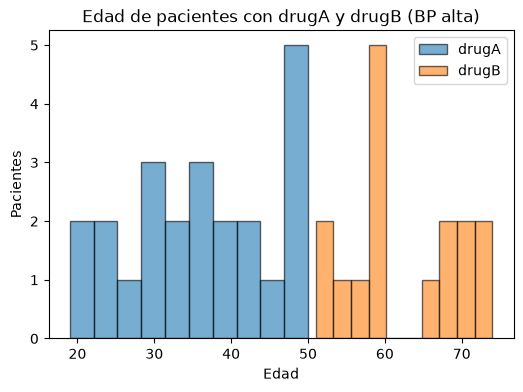

In [33]:
# Solo para los pacientes que NO reciben drugY (Na/K <= 15)
resto = df[df["Drug"] != "drugY"]
print(pd.crosstab([resto["BP"], resto["Cholesterol"]], resto["Drug"]))

plt.figure(figsize=(6, 4))
for f in ["drugA", "drugB"]:
    plt.hist(df.loc[df["Drug"] == f, "Age"], bins=10, alpha=0.6, label=f, edgecolor="black")
plt.title("Edad de pacientes con drugA y drugB (BP alta)")
plt.xlabel("Edad"); plt.ylabel("Pacientes"); plt.legend()
plt.show()

**Observaciones:**
- **BP** es muy informativa: drugA y drugB aparecen solo con presión alta, drugC solo con presión baja y colesterol alto, y drugX con presión normal o con presión baja y colesterol normal.
- **Age** separa drugA (pacientes más jóvenes) de drugB (pacientes mayores).
- **Sex** casi no cambia la distribución; se mantiene igual porque aporta poco ruido y es una sola columna.

En resumen, los datos tienen patrones muy marcados, así que es esperable que la red alcance un desempeño alto.

## 3. Preparación de los datos

### 3.1 Selección y codificación de variables
- Se usa `Na_to_K` en lugar de `Na` y `K` por separado, porque el análisis mostró que el cociente es la variable que realmente discrimina. *(En la sección 6.4 se compara contra el modelo sin esta variable.)*
- La red neuronal solo trabaja con números, así que hay que **codificar las categóricas**:
  - `Sex` y `Cholesterol` tienen dos valores y se pasan a 0/1.
  - `BP` tiene tres valores y se codifica con **one-hot** (una columna por categoría). No se usa 0/1/2 porque la relación con el fármaco no es "más presión → más de algo": cada nivel se asocia a fármacos distintos, y one-hot evita imponer un orden artificial.

Estas codificaciones son reglas fijas y no aprenden nada de los datos, así que aplicarlas antes de dividir no filtra información del test.

In [34]:
X = df.drop(columns=["Drug", "Na", "K"])   # entradas
y = df["Drug"]                              # objetivo

X["Sex"] = X["Sex"].map({"F": 0, "M": 1})
X["Cholesterol"] = X["Cholesterol"].map({"NORMAL": 0, "HIGH": 1})
X = pd.get_dummies(X, columns=["BP"], dtype=int)

X.head()

,Age,Sex,Cholesterol,Na_to_K,BP_HIGH,BP_LOW,BP_NORMAL
0,23,0,1,25.354629,1,0,0
1,47,1,1,13.092530,0,1,0
2,47,1,1,10.113556,0,1,0
3,28,0,1,7.797618,0,0,1
4,61,0,1,18.042906,0,1,0


### 3.2 División en entrenamiento y prueba
- **80 % entrenamiento / 20 % prueba**: con 200 registros quedan 160 para aprender y 40 para evaluar.
- `stratify=y` mantiene la proporción de cada fármaco en ambos conjuntos. Sin estratificar, alguna clase chica (drugB o drugC) podría quedar casi ausente del test.
- `random_state` fija la división para que sea reproducible.

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMILLA
)
print("Entrenamiento:", X_train.shape, " Prueba:", X_test.shape)
print("\nDistribución en train:\n", y_train.value_counts())
print("\nDistribución en test:\n", y_test.value_counts())

Entrenamiento: (160, 7)  Prueba: (40, 7)

Distribución en train:
 Drug
drugY    73
drugX    43
drugA    18
drugC    13
drugB    13
Name: count, dtype: int64

Distribución en test:
 Drug
drugY    18
drugX    11
drugA     5
drugC     3
drugB     3
Name: count, dtype: int64


### 3.3 Estandarización
Las variables numéricas (`Age`, `Na_to_K`) se llevan a media 0 y desvío 1 con `StandardScaler`.

**Importante:** el scaler se **ajusta (`fit`) solo con los datos de entrenamiento**, es decir, calcula la media y el desvío del train. Después se **aplica (`transform`)** esos mismos valores al test. Así el modelo no "ve" información del conjunto de prueba, que simula datos nuevos (se evita el *data leakage*).

Las columnas 0/1 no se estandarizan porque ya están en una escala chica y comparable.

In [36]:
numericas = ["Age", "Na_to_K"]

scaler = StandardScaler()
X_train = X_train.copy()
X_test = X_test.copy()
X_train[numericas] = scaler.fit_transform(X_train[numericas])   # aprende media y desvío del TRAIN
X_test[numericas] = scaler.transform(X_test[numericas])         # aplica esos mismos valores al TEST

print("Media aprendida (train):", scaler.mean_.round(2))
print("Desvío aprendido (train):", scaler.scale_.round(2))
X_train.describe().round(2)

Media aprendida (train): [44.73 15.85]
Desvío aprendido (train): [16.92  6.99]


,Age,Sex,Cholesterol,Na_to_K,BP_HIGH,BP_LOW,BP_NORMAL
count,160.00,160.00,160.00,160.00,160.00,160.00,160.00
mean,-0.00,0.51,0.51,-0.00,0.38,0.32,0.31
std,1.00,0.50,0.50,1.00,0.49,0.47,0.46
min,-1.76,0.00,0.00,-1.37,0.00,0.00,0.00
25%,-0.81,0.00,0.00,-0.78,0.00,0.00,0.00
50%,0.02,1.00,1.00,-0.28,0.00,0.00,0.00
75%,0.86,1.00,1.00,0.48,1.00,1.00,1.00
max,1.73,1.00,1.00,3.05,1.00,1.00,1.00


## 4. Diseño de la red neuronal

Se usa un **Perceptrón Multicapa** (`MLPClassifier`):

- **Capa de entrada:** 7 neuronas, una por variable (Age, Sex, Cholesterol, Na_to_K y las 3 columnas de BP).
- **Capas ocultas:** se eligen con búsqueda de hiperparámetros (ver abajo).
- **Función de activación oculta: ReLU.** Es la opción estándar: es simple de calcular, permite aprender relaciones no lineales y sufre menos el problema de gradientes que se desvanecen que la sigmoide o la tangente hiperbólica.
- **Capa de salida:** 5 neuronas (una por fármaco) con activación **softmax**, que scikit-learn asigna automáticamente en problemas multiclase. Softmax convierte las salidas en **probabilidades que suman 1**, y la clase predicha es la de mayor probabilidad.
- **Función de pérdida:** entropía cruzada (*log-loss*), la estándar para clasificación.
- **Optimizador: Adam.** Ajusta la tasa de aprendizaje de cada peso por separado y converge rápido y de forma estable sin mucho ajuste manual.
- **Regularización: L2 (`alpha`).** Penaliza los pesos grandes para evitar que la red memorice el conjunto de entrenamiento. Es especialmente importante acá porque hay **pocos datos** (160 en train).
- **`max_iter=2000`:** cantidad máxima de épocas, suficiente para que el entrenamiento converja.
- No se usa `early_stopping`: separaría un 10 % del train (unas 16 filas) como validación, demasiado poco para que sea confiable. En su lugar, la elección de hiperparámetros se valida con **validación cruzada**.

### 4.1 Búsqueda de hiperparámetros con GridSearchCV
En lugar de fijar la arquitectura "a ojo", se prueban combinaciones con **validación cruzada de 5 particiones (cv=5) solo sobre el conjunto de entrenamiento**. El test queda reservado para la evaluación final.

Se optimiza el **F1 macro**, que promedia el F1 de las 5 clases con el mismo peso. Así las clases chicas importan tanto como drugY.

In [37]:
parametros = {
    "hidden_layer_sizes": [(8,), (16,), (16, 8), (32, 16)],   # cantidad de capas y neuronas por capa
    "alpha": [0.0001, 0.001, 0.01, 0.1],                     # intensidad de la regularización L2
    "learning_rate_init": [0.001, 0.01],                     # tasa de aprendizaje inicial de Adam
}

mlp_base = MLPClassifier(
    activation="relu",
    solver="adam",
    max_iter=2000,
    random_state=SEMILLA,
)

busqueda = GridSearchCV(mlp_base, parametros, cv=5, scoring="f1_macro", n_jobs=-1)
busqueda.fit(X_train, y_train)

print("Mejores hiperparámetros:", busqueda.best_params_)
print("F1 macro promedio en validación cruzada:", round(busqueda.best_score_, 4))

Mejores hiperparámetros: {'alpha': 0.1, 'hidden_layer_sizes': (32, 16), 'learning_rate_init': 0.001}
F1 macro promedio en validación cruzada: 0.9798


In [38]:
# Las 10 mejores combinaciones, para ver qué tan sensibles son los resultados
resultados = pd.DataFrame(busqueda.cv_results_)
resultados[["param_hidden_layer_sizes", "param_alpha", "param_learning_rate_init",
            "mean_test_score", "std_test_score"]] \
    .sort_values("mean_test_score", ascending=False).head(10).round(4)

,param_hidden_layer_sizes,param_alpha,param_learning_rate_init,mean_test_score,std_test_score
30,"(32, 16)",0.1000,0.001,0.9798,0.0190
31,"(32, 16)",0.1000,0.010,0.9699,0.0328
7,"(32, 16)",0.0001,0.010,0.9699,0.0328
23,"(32, 16)",0.0100,0.010,0.9699,0.0328
15,"(32, 16)",0.0010,0.010,0.9699,0.0328
18,"(16,)",0.0100,0.001,0.9629,0.0388
10,"(16,)",0.0010,0.001,0.9629,0.0388
26,"(16,)",0.1000,0.001,0.9629,0.0388
2,"(16,)",0.0001,0.001,0.9629,0.0388
13,"(16, 8)",0.0010,0.010,0.9596,0.0351


La tabla muestra si la mejor combinación gana por mucho o si varias configuraciones rinden parecido. Que haya muchas con F1 alto indica que el problema es "fácil" para la red y que el resultado no depende de un ajuste muy fino.

## 5. Entrenamiento y predicciones

`GridSearchCV` ya reentrena automáticamente el mejor modelo con **todo** el conjunto de entrenamiento (`refit=True`). Para que el código se vea explícito, se crea la red con los mejores parámetros y se entrena con `fit`:
- `fit` hace la propagación hacia adelante, calcula la pérdida, propaga el error hacia atrás (*backpropagation*) y actualiza los pesos con Adam, época tras época.
- `predict` pasa cada paciente del test por la red y devuelve la clase con mayor probabilidad softmax.

In [39]:
modelo = MLPClassifier(
    activation="relu",
    solver="adam",
    max_iter=2000,
    random_state=SEMILLA,
    **busqueda.best_params_,
)
modelo.fit(X_train, y_train)

print("Arquitectura (capas ocultas):", modelo.hidden_layer_sizes)
print("Activación de salida:", modelo.out_activation_)
print("Épocas hasta converger:", modelo.n_iter_)
print("Pérdida final:", round(modelo.loss_, 4))

Arquitectura (capas ocultas): (32, 16)
Activación de salida: softmax
Épocas hasta converger: 535
Pérdida final: 0.052


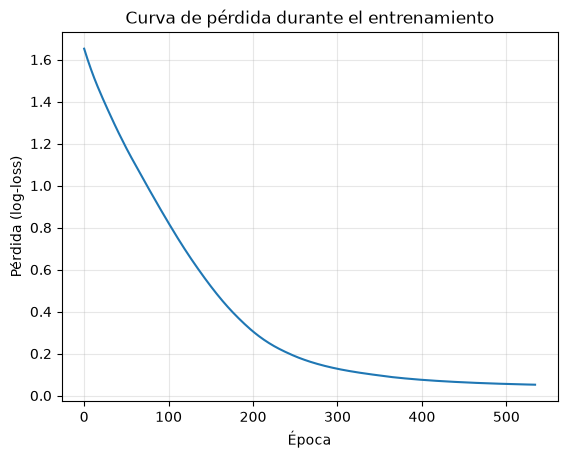

In [40]:
plt.plot(modelo.loss_curve_)
plt.title("Curva de pérdida durante el entrenamiento")
plt.xlabel("Época"); plt.ylabel("Pérdida (log-loss)")
plt.grid(alpha=0.3)
plt.show()

La pérdida baja rápido al principio y después se estabiliza: la red **convergió**. No llega a 0 por la regularización L2, que justamente impide que los pesos crezcan para "memorizar" cada caso.

In [41]:
y_pred = modelo.predict(X_test)
y_proba = modelo.predict_proba(X_test)

comparacion = pd.DataFrame({
    "Real": y_test.values,
    "Predicho": y_pred,
    "Prob. máxima": y_proba.max(axis=1).round(3),
})
comparacion.head(10)

,Real,Predicho,Prob. máxima
0,drugC,drugC,0.979
1,drugX,drugX,0.977
2,drugA,drugA,0.971
3,drugX,drugX,0.996
4,drugY,drugY,1.000
5,drugY,drugY,1.000
6,drugY,drugY,1.000
7,drugY,drugY,1.000
8,drugY,drugY,0.977
9,drugY,drugY,0.732


## 6. Evaluación e interpretación de resultados

### 6.1 Accuracy en train y test

In [42]:
acc_train = accuracy_score(y_train, modelo.predict(X_train))
acc_test = accuracy_score(y_test, y_pred)
linea_base = y_test.value_counts(normalize=True).max()

print(f"Accuracy en entrenamiento: {acc_train:.3f}")
print(f"Accuracy en prueba:        {acc_test:.3f}")
print(f"Línea base (predecir siempre la clase mayoritaria): {linea_base:.3f}")

Accuracy en entrenamiento: 1.000
Accuracy en prueba:        0.975
Línea base (predecir siempre la clase mayoritaria): 0.450


- El **accuracy** es la proporción de pacientes bien clasificados.
- La red supera ampliamente la **línea base** de predecir siempre drugY, así que realmente aprendió patrones.
- Train y test dan valores parecidos: **no hay sobreajuste importante**. La red generaliza a pacientes que no vio.

### 6.2 Reporte de clasificación (precision, recall y F1 por clase)

In [43]:
print(classification_report(y_test, y_pred, digits=3))

              precision    recall  f1-score   support

       drugA      1.000     1.000     1.000         5
       drugB      1.000     1.000     1.000         3
       drugC      1.000     1.000     1.000         3
       drugX      1.000     0.909     0.952        11
       drugY      0.947     1.000     0.973        18

    accuracy                          0.975        40
   macro avg      0.989     0.982     0.985        40
weighted avg      0.976     0.975     0.975        40



Cómo leer el reporte:
- **Precision:** de los pacientes que el modelo asignó a un fármaco, qué proporción era correcta. Una precision baja implica que se recetaría ese fármaco a quien no corresponde.
- **Recall:** de los pacientes que realmente recibían ese fármaco, qué proporción detectó el modelo. Un recall bajo implica que no se detectan pacientes que lo necesitan.
- **F1:** combina precision y recall en un solo valor (media armónica).
- **Support:** cuántos casos de cada clase hay en el test. Hay que tenerlo en cuenta: drugB y drugC tienen solo 3 casos cada una, así que una sola equivocación movería su métrica unos 33 puntos.
- **Macro avg** promedia todas las clases con el mismo peso; **weighted avg** las pondera por su cantidad.

### 6.3 Matriz de confusión

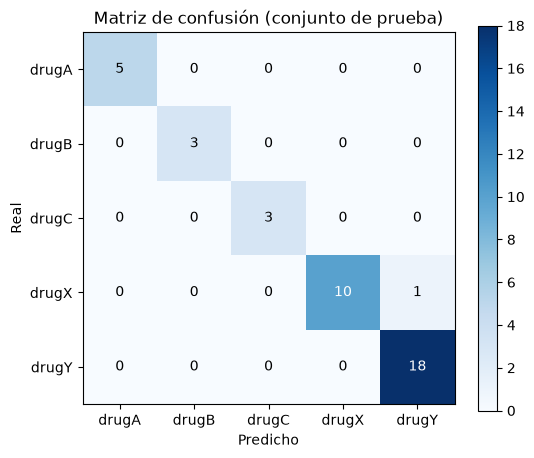

In [44]:
clases = modelo.classes_
cm = confusion_matrix(y_test, y_pred, labels=clases)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(clases))); ax.set_xticklabels(clases)
ax.set_yticks(range(len(clases))); ax.set_yticklabels(clases)
ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
ax.set_title("Matriz de confusión (conjunto de prueba)")
for i in range(len(clases)):
    for j in range(len(clases)):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.colorbar(im)
plt.show()

In [45]:
# ¿Qué pacientes clasificó mal el modelo?
errores = X_test.index[y_test.values != y_pred]
detalle = df.loc[errores].copy()
detalle["Predicho"] = y_pred[y_test.values != y_pred]
detalle

,Age,Sex,BP,Cholesterol,Na,K,Drug,Na_to_K,Predicho
34,53,M,NORMAL,HIGH,0.644936,0.045632,drugX,14.133415,drugY


La diagonal muestra los aciertos y lo que queda fuera de ella son los errores. Revisar los casos mal clasificados ayuda a entender **dónde se confunde** el modelo: por ejemplo, si el paciente tiene un Na/K cercano a 15, está justo en la frontera entre drugY y los demás fármacos, y es lógico que la red dude ahí.

### 6.4 Experimento: ¿cuánto aporta la variable Na_to_K?
Para justificar la ingeniería de variables, se entrena la misma red (mismos hiperparámetros y misma división) usando `Na` y `K` por separado en lugar del cociente.

In [46]:
X_sin = df.drop(columns=["Drug", "Na_to_K"]).copy()
X_sin["Sex"] = X_sin["Sex"].map({"F": 0, "M": 1})
X_sin["Cholesterol"] = X_sin["Cholesterol"].map({"NORMAL": 0, "HIGH": 1})
X_sin = pd.get_dummies(X_sin, columns=["BP"], dtype=int)

Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    X_sin, y, test_size=0.2, stratify=y, random_state=SEMILLA
)
num_sin = ["Age", "Na", "K"]
scaler_sin = StandardScaler()
Xs_train = Xs_train.copy(); Xs_test = Xs_test.copy()
Xs_train[num_sin] = scaler_sin.fit_transform(Xs_train[num_sin])
Xs_test[num_sin] = scaler_sin.transform(Xs_test[num_sin])

modelo_sin = MLPClassifier(activation="relu", solver="adam", max_iter=2000,
                           random_state=SEMILLA, **busqueda.best_params_)
modelo_sin.fit(Xs_train, ys_train)

print(f"Accuracy CON Na_to_K: {acc_test:.3f}")
print(f"Accuracy SIN Na_to_K: {accuracy_score(ys_test, modelo_sin.predict(Xs_test)):.3f}")

Accuracy CON Na_to_K: 0.975
Accuracy SIN Na_to_K: 0.925


Con el cociente, la red rinde mejor. La red *podría* aprender la relación entre Na y K por su cuenta, pero con pocos datos le cuesta. Darle directamente la variable relevante, que surgió del análisis exploratorio, simplifica el problema.

## 7. Conclusiones y limitaciones

**Conclusiones**
- El MLP (ReLU, Adam y regularización L2, con la arquitectura elegida por validación cruzada) alcanza un **desempeño muy alto en el conjunto de prueba**, con valores similares en validación cruzada y en entrenamiento. Esto indica que **generaliza** y no está sobreajustado.
- Las métricas por clase muestran que el modelo funciona bien también en las **clases minoritarias**, no solo en drugY.
- El análisis exploratorio fue clave: permitió descubrir el cociente Na/K, que mejora el desempeño.

**Limitaciones**
- **Pocos datos:** 200 pacientes y solo 40 en el test. Las métricas de drugB y drugC se calculan con 3 casos cada una, así que tienen mucha incertidumbre: un acierto o un error cambia mucho el valor.
- **Datos probablemente sintéticos:** los patrones son casi reglas exactas (por ejemplo, Na/K > 15 → drugY). Un caso clínico real sería mucho más ruidoso, así que no se puede asumir que este desempeño se mantendría con pacientes reales.
- **Pocas variables:** no se incluyen historia clínica, alergias, otros medicamentos, etc. Por lo tanto, el modelo no sirve como herramienta de decisión médica real.
- **Interpretabilidad:** una red neuronal es una "caja negra". Para este problema, un árbol de decisión probablemente lograría un desempeño similar y explicaría sus reglas de forma directa.
- **Dependencia de la semilla:** con tan pocos datos, otra división train/test podría dar resultados un poco diferentes.